# LH2 흡입배관: 물리식과 AI의 역할
## 1. 연구 목적과 하이브리드 구조
열침입과 압력 손실을 줄이면서 외경이 작은 배관을 찾는다. 데이터는 **1D 솔버 출력**이며 실험값이 아니다.

외경은 $D_o=D+3+2t_{ins}$, 강체 압력은 물리식으로 계산한다. 수력 압력은 기본적으로 강체 압력의 1.8배이며, GPR 비율 보정을 함께 비교한다. **AI의 핵심 역할은 열적 압력 손실 `dp_thermal` 예측**이다. 열침입 `Q_leak`는 물리식으로 충분한지 확인한다.

원본은 두 출력 모두 GPR을 선정했다. 재현의 일관성을 위해 두 출력의 GPR과 비교 모델 MLP를 그대로 학습하며, 최적화에서도 원본의 열침입 GPR을 유지한다.

이 노트북은 저장된 선정 설정을 재현한다. 튜닝·모델 재선정·`finalize` 재실행은 하지 않는다. 최종 테스트는 재현 수치 비교에만 사용한다.

In [1]:
from pathlib import Path
import os, sys, json, time, hashlib

start = time.perf_counter()
base = Path.cwd()
if not (base / 'full_pipeline').is_dir():
    base = base / 'submission'
assert (base / 'full_pipeline').is_dir(), 'submission 폴더에서 실행하세요.'
os.environ['MPLCONFIGDIR'] = str(Path('/tmp') / 'lh2_submission_mpl')
sys.path.insert(0, str(base / 'full_pipeline'))

import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
from threadpoolctl import threadpool_limits
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.gaussian_process import GaussianProcessRegressor, kernels
from sklearn.neural_network import MLPRegressor
import lh2_pipeline as p
from physics_baseline import physics_heat_leak, PhysicsFeatureTransformer
from hydraulics import pressure_metrics

# 원본의 BLAS 1 thread와 맞춰 연산 순서와 메모리 사용을 일정하게 한다.
threads = threadpool_limits(limits=1)
np.random.seed(2026)
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda x: f'{x:.9g}')
results = base / 'results'
ref = results / 'reproduction'
manifest = json.loads((ref / 'manifest.json').read_text())
fixed = json.loads((ref / 'fixed_parameters.json').read_text())
assert manifest['seed'] == 2026
assert manifest['effective_config']['physics_feature']
assert manifest['selected'] == {'Q_leak_W': 'gpr', 'dp_thermal_Pa': 'gpr'}
display(pd.read_json(ref / 'environment.json', typ='series').to_frame('실행 환경'))

,실행 환경
os,Ubuntu 22.04.5 LTS
python,3.10.12
packages,"{'numpy': '2.2.6', 'pandas': '2.3.3', 'scipy':..."
ram_gib,15.21
seed,2026


## 2. 데이터와 물리 일관성
입력은 아래 6개뿐이다. `log10_k_MLI`는 열전도도의 상용로그다. ID와 정답, 기화 라벨은 모델 입력에서 제외한다.

| 구분 | 열 | 단위·의미 |
|---|---|---|
| 입력 | D_mm, t_ins_mm | 내경·단열 두께 [mm] |
| 입력 | f_Hz, L_m, mdot_kg_h | 주파수 [Hz]·길이 [m]·질량유량 [kg/h] |
| 입력 | log10_k_MLI | 열전도도 [W/(m·K)]의 log10 |
| 보조 | k_MLI_W_mK | 열전도도 원값 |
| 정답 | Q_leak_W, log10_Q_leak | 열침입 [W]·상용로그 |
| 정답 | dp_thermal_Pa, dp_hyd_Pa, dp_design_Pa | 열적·수력·전체 압력 손실 [Pa] |
| 확인용 | D_o_mm, dp_rigid_Pa | 외경 [mm]·강체 압력 [Pa] |
| 식별·분할용 | case_id, vaporized | ID·48,300 Pa 초과 여부 |

강체 압력은 $A=\pi(D/1000)^2/4$, $\Delta p_{rigid}=L(\pi\dot m/3600)(2\pi f)/A$이다. 원본 로더의 반올림 허용오차로 외경·압력 성분·기화 라벨을 확인해 열 순서나 단위 오류를 먼저 찾는다.

In [2]:
path = base / 'data' / 'dataset_ai_10k.csv'
assert hashlib.sha256(path.read_bytes()).hexdigest() == manifest['data_sha256']
df = p.load_data(path)
checks = pd.DataFrame({
    '확인 항목': ['외경 식', '강체 압력식', '전체 압력 = 수력 + 열적'],
    '최대 절대 차이': [np.max(np.abs(df.D_o_mm - (df.D_mm + 3 + 2*df.t_ins_mm))),
                  np.max(np.abs(df.dp_rigid_Pa - p.rigid_pressure(df))),
                  np.max(np.abs(df.dp_design_Pa - df.dp_hyd_Pa - df.dp_thermal_Pa))],
    '단위': ['mm', 'Pa', 'Pa']})
display(checks)
print(f'데이터 {len(df):,}개, 기화 비율 {df.vaporized.mean():.2%}')
display(df.head(3))

,확인 항목,최대 절대 차이,단위
0,외경 식,1.42108547e-14,mm
1,강체 압력식,0.249284514,Pa
2,전체 압력 = 수력 + 열적,0.94,Pa


데이터 10,000개, 기화 비율 8.13%


,case_id,D_mm,t_ins_mm,f_Hz,L_m,mdot_kg_h,k_MLI_W_mK,log10_k_MLI,Q_leak_W,log10_Q_leak,dp_thermal_Pa,dp_hyd_Pa,dp_design_Pa,vaporized,D_o_mm,dp_rigid_Pa
0,100001,42.244,16.2218,4.06071,2.4524,74.4635,0.000478055,-3.32052214,3.74842974,0.573849375,966.392,5182.2,6148.59,0,77.6876,2900.98
1,100002,32.0385,8.2479,8.68089,2.25605,60.6507,0.000866819,-3.06207158,8.64864133,0.936947887,2746.13,14289.6,17035.7,0,51.5343,8078.71
2,100003,16.8998,17.5969,9.17999,2.81805,81.4022,0.00293017,-2.53310718,13.78832,1.13951135,4725.93,93542.5,98268.5,1,55.0936,51475.6


## 3. 개발 데이터와 최종 테스트
seed 2026, `vaporized` 층화, 최종 테스트 20%를 그대로 사용한다. 새 분할의 ID 집합이 원본과 같은지 확인한다. 개발 데이터의 행 순서도 유지해야 MLP 내부 검증 분할과 GPR 부분표본이 같아진다.

In [3]:
train_idx, test_idx = train_test_split(np.arange(len(df)), test_size=0.2,
                                      stratify=df.vaporized, random_state=2026)
split = pd.read_csv(ref / 'split.csv')
assert set(df.iloc[train_idx].case_id) == set(split.loc[split.split == 'development', 'case_id'])
assert set(df.iloc[test_idx].case_id) == set(split.loc[split.split == 'test', 'case_id'])
dev = df.iloc[train_idx].copy()
# 원본 finalize는 split.csv 순서로 읽으므로 최종 테스트도 그 순서로 맞춘다.
test = df.set_index('case_id').loc[split.loc[split.split == 'test', 'case_id']].reset_index()
assert len(dev) == 8000 and len(test) == 2000
print(f'원본 ID 일치: 개발 데이터 {len(dev):,}개 / 최종 테스트 {len(test):,}개')

원본 ID 일치: 개발 데이터 8,000개 / 최종 테스트 2,000개


## 4. 열침입 물리식 기준선
원통 단열층의 전도 저항과 외부 대류 저항을 더한다. 상수는 원본 `physics_baseline`과 같고 튜닝하지 않는다.

$r_i=D/2000$, $r_w=r_i+0.0015$, $r_o=r_w+t_{ins}/1000$ [m]

$R=\ln(r_o/r_w)/(2\pi kL)+1/(5\cdot2\pi r_o L)$, $Q_{phys}=(300-23.6)/R$ [W]

벽의 열저항은 무시한다. 먼저 개발 데이터에서 물리식 오차를 확인한다. AI를 쓸 필요가 있는 출력과 식만으로 충분한 출력을 구분하기 위해서다.

In [4]:
q_dev = physics_heat_leak(dev[p.FEATURES])
display(pd.DataFrame([{'대상': '개발 데이터 열침입 물리식',
                       **p.metrics(dev.Q_leak_W, q_dev),
                       '최대 상대 오차(%)': np.max(100*np.abs(q_dev/dev.Q_leak_W-1))}]))

,대상,r2,rmse,mape_pct,log10_rmse,log10_r2,최대 상대 오차(%)
0,개발 데이터 열침입 물리식,0.999975442,0.0944113681,0.062703999,0.000488063211,0.999999447,1.11552121


## 5. 물리 특성
$\log_{10}(Q_{phys}/\dot m)$는 유량당 열 유입의 크기를 나타낸다. 입력 6개로만 계산하므로 정답이 필요 없다. 단위는 원본처럼 W와 kg/h를 사용한다.

특성 생성과 스케일러를 Pipeline 안에 두고 개발 데이터에만 fit한다. `dp_thermal`은 값의 범위가 수백 배라 log10으로 학습한다. 열침입 비교 모델도 원본과 같은 log10 변환을 쓴다.

In [5]:
feature = PhysicsFeatureTransformer(tuple(p.FEATURES))
x_dev = dev[p.FEATURES]
x_test = test[p.FEATURES]
display(feature.fit_transform(x_dev).head(3))
assert x_dev.columns.tolist() == p.FEATURES

,D_mm,t_ins_mm,f_Hz,L_m,mdot_kg_h,log10_k_MLI,log10_Q_phys_per_mdot
9086,32.8266,12.4439,8.93626,2.66635,70.2015,-3.14956453,-1.05631731
5077,41.066,21.6721,5.20476,1.97815,83.7202,-3.07023582,-1.29519235
2741,29.1961,14.8269,2.78725,2.9841,80.9044,-3.42073673,-1.43063086


## 6. 선정 설정으로 최종 모델 학습
T2의 커널 표기는 반올림되어 있다. 원본 학습 모델에서 **전체 정밀도의 학습된 커널**을 추출한 `fixed_parameters.json`을 사용한다. 커널 구조·alpha·MLP 설정은 원본 그대로이며 GPR은 `optimizer=None`으로 고정한다.

GPR은 저장된 3,000개 부분표본 ID와 행 순서를 그대로 사용한다. MLP는 원본처럼 개발 데이터 8,000개를 사용하고 내부 조기 종료 검증도 유지한다. 커널 최적화를 생략해 실행 시간을 줄이며, 최종 테스트로 설정을 바꾸지 않는다.

In [6]:
def read_kernel(spec):
    # eval 대신 저장된 커널의 구조와 숫자만 복원한다.
    params = {k: read_kernel(v) if isinstance(v, dict) and 'class' in v else v
              for k, v in spec['params'].items()}
    return getattr(kernels, spec['class'])(**params)

samples = pd.read_csv(ref / 'gpr_subsamples.csv')
models = {}
fit_rows = []
for target in p.TARGETS:
    for name in ['gpr', 'mlp']:
        key = target + '__' + name
        params = fixed[key].copy()
        if name == 'gpr':
            params['kernel'] = read_kernel(params['kernel'])
            assert params['optimizer'] is None
            ids = samples.loc[(samples.target == target) & (samples.stage == 'refit'), 'case_id']
            assert len(ids) == 3000 and ids.is_unique and set(ids) <= set(dev.case_id)
            data = dev.set_index('case_id').loc[ids]
            estimator = GaussianProcessRegressor(**params)
        else:
            data = dev
            params['hidden_layer_sizes'] = tuple(params['hidden_layer_sizes'])
            estimator = MLPRegressor(**params)
        pipe = Pipeline([('physics_feature', PhysicsFeatureTransformer(tuple(p.FEATURES))),
                         ('scale', StandardScaler()), ('model', estimator)])
        model = TransformedTargetRegressor(regressor=pipe, func=np.log10, inverse_func=p.exp10)
        tick = time.perf_counter()
        model.fit(data[p.FEATURES], data[target])
        models[key] = model
        fit_rows.append({'출력': target, '모델': name, '학습 행 수': len(data),
                         '학습 시간(초)': time.perf_counter()-tick})
display(pd.DataFrame(fit_rows))

,출력,모델,학습 행 수,학습 시간(초)
0,Q_leak_W,gpr,3000,0.595556286
1,Q_leak_W,mlp,8000,0.417546891
2,dp_thermal_Pa,gpr,3000,0.663421275
3,dp_thermal_Pa,mlp,8000,1.29936228


## 7. 최종 테스트 재현 비교
원본의 `T_final_test_metrics.csv`와 R²·RMSE·MAPE를 나란히 둔다. 차이는 **노트북 − 원본**이다. RMSE 단위는 열침입 W, 열적 압력 Pa이며 MAPE 차이는 %p다. 물리식은 별도로 제시한다.

같은 설정이어도 패키지·BLAS·부동소수점 연산에 따라 작은 차이가 날 수 있다. 아래 표와 예측값 차이를 모두 남겨 차이의 크기를 확인한다.

In [7]:
pred = {key: model.predict(x_test) for key, model in models.items()}
rows = [{'target': target, 'model': name, **p.metrics(test[target], pred[target+'__'+name])}
        for target in p.TARGETS for name in ['gpr', 'mlp']]
metrics = pd.DataFrame(rows)
original = pd.read_csv(results / 'T_final_test_metrics.csv')
comparison = metrics.merge(original, on=['target','model'], suffixes=('_notebook','_original'))
cols = ['target','model']
for metric in ['r2','rmse','mape_pct']:
    comparison[metric+'_difference'] = comparison[metric+'_notebook'] - comparison[metric+'_original']
    cols += [metric+'_original', metric+'_notebook', metric+'_difference']
view = pd.concat([comparison[['target','model', metric+'_original', metric+'_notebook', metric+'_difference']]
                  .rename(columns={metric+'_original':'원본', metric+'_notebook':'노트북',
                                   metric+'_difference':'차이'}).assign(지표=metric)
                  for metric in ['r2','rmse','mape_pct']], ignore_index=True)
display(view[['target','model','지표','원본','노트북','차이']])
saved = pd.read_csv(ref / 'final_test_predictions.csv').set_index('case_id').loc[test.case_id]
pred_diff = pd.DataFrame([{'모델': key, '최대 예측 절대 차이': np.max(np.abs(values-saved[key].to_numpy()))}
                          for key, values in pred.items()])
display(pred_diff)
display(pd.DataFrame([{'모델': 'physics_baseline', **p.metrics(test.Q_leak_W, physics_heat_leak(x_test))}]))
# 원본 표와 구분하여 저장한다. 재실행해도 원본 결과는 덮어쓰지 않는다.
comparison[cols].to_csv(ref / 'notebook_test_comparison.csv', index=False)
pred_diff.to_csv(ref / 'notebook_prediction_difference.csv', index=False)

,target,model,지표,원본,노트북,차이
0,Q_leak_W,gpr,r2,0.999999991,0.999999991,4.3298698e-15
1,Q_leak_W,mlp,r2,0.999490291,0.999490291,0
2,dp_thermal_Pa,gpr,r2,0.999981371,0.999981371,1.91735516e-13
3,dp_thermal_Pa,mlp,r2,0.995340812,0.995340812,-1.11022302e-16
4,Q_leak_W,gpr,rmse,0.00196560451,0.00196560405,-4.5654874e-10
5,Q_leak_W,mlp,rmse,0.467578881,0.467578881,5.55111512e-17
6,dp_thermal_Pa,gpr,rmse,23.0500659,23.0500658,-1.18538324e-07
7,dp_thermal_Pa,mlp,rmse,364.533116,364.533116,0
8,Q_leak_W,gpr,mape_pct,0.00108741616,0.00108741758,1.41675393e-09
9,Q_leak_W,mlp,mape_pct,0.871363695,0.871363695,0


,모델,최대 예측 절대 차이
0,Q_leak_W__gpr,7.04599337e-07
1,Q_leak_W__mlp,2.84217094e-14
2,dp_thermal_Pa__gpr,6.08276168e-05
3,dp_thermal_Pa__mlp,7.27595761e-12


,모델,r2,rmse,mape_pct,log10_rmse,log10_r2
0,physics_baseline,0.999965823,0.121076223,0.0653253984,0.000532031827,0.999999369


## 8. 수력 보정과 전체 압력
전체 압력은 $\Delta p_{design}=\widehat{\Delta p}_{thermal}+r\Delta p_{rigid}$로 조립한다. $r=1.8$과 입력 6개로 예측하는 GPR 비율을 비교한다. 비율 GPR도 원본 학습된 커널과 부분표본을 고정하며 물리 특성은 추가하지 않는다.

경계 구간은 실제 전체 압력 38.3–58.3 kPa, 제약은 48.3 kPa 이하이다. `false safe`는 실제 초과를 안전으로, `false unsafe`는 실제 안전을 초과로 예측한 개수다. 이 구분은 후보 설계를 솔버로 다시 확인해야 하는 이유를 보여 준다.

In [8]:
hyd_samples = pd.read_csv(ref / 'hydraulic_subsamples.csv')
ids = hyd_samples.loc[hyd_samples.stage == 'refit', 'case_id']
assert len(ids) == 3000 and ids.is_unique and set(ids) <= set(dev.case_id)
hyd_data = dev.set_index('case_id').loc[ids]
params = fixed['hyd_ratio__gpr'].copy()
params['kernel'] = read_kernel(params['kernel'])
assert params['optimizer'] is None
ratio = Pipeline([('scale', StandardScaler()), ('model', GaussianProcessRegressor(**params))])
ratio.fit(hyd_data[p.FEATURES], hyd_data.dp_hyd_Pa/hyd_data.dp_rigid_Pa)
rigid = p.rigid_pressure(test)
thermal = pred['dp_thermal_Pa__gpr']
pressure = {'const': thermal+1.8*rigid, 'gpr': thermal+ratio.predict(x_test)*rigid}
hyd = pd.DataFrame([{'hyd_model': name, **pressure_metrics(test.dp_design_Pa, values)}
                    for name, values in pressure.items()])
hyd_original = pd.read_csv(ref / 'final_pressure_comparison.csv')
hyd_compare = hyd.merge(hyd_original, on='hyd_model', suffixes=('_notebook','_original'))
for col in ['mape_pct','boundary_mape_pct','false_safe_count','false_unsafe_count']:
    hyd_compare[col+'_difference'] = hyd_compare[col+'_notebook']-hyd_compare[col+'_original']
display(hyd[['hyd_model','n','mape_pct','boundary_n','boundary_mape_pct','false_safe_count','false_unsafe_count']])
hyd_view = pd.concat([hyd_compare[['hyd_model', col+'_original', col+'_notebook', col+'_difference']]
                      .rename(columns={col+'_original':'원본', col+'_notebook':'노트북', col+'_difference':'차이'})
                      .assign(지표=col) for col in ['mape_pct','boundary_mape_pct','false_safe_count','false_unsafe_count']],
                     ignore_index=True)
display(hyd_view[['hyd_model','지표','원본','노트북','차이']])
hyd_compare.to_csv(ref / 'notebook_hydraulic_comparison.csv', index=False)

,hyd_model,n,mape_pct,boundary_n,boundary_mape_pct,false_safe_count,false_unsafe_count
0,const,2000,0.687533271,134,0.951264697,1,4
1,gpr,2000,0.0737938437,134,0.0894014574,0,0


,hyd_model,지표,원본,노트북,차이
0,const,mape_pct,0.687533271,0.687533271,1.98031591e-11
1,gpr,mape_pct,0.0737938436,0.0737938437,4.30394609e-11
2,const,boundary_mape_pct,0.951264697,0.951264697,1.67238445e-11
3,gpr,boundary_mape_pct,0.0894014574,0.0894014574,-1.67236225e-11
4,const,false_safe_count,1,1,0
5,gpr,false_safe_count,0,0,0
6,const,false_unsafe_count,4,4,0
7,gpr,false_unsafe_count,0,0,0


## 9. 원본 모델 비교와 학습 곡선
**튜닝 50회와 학습 곡선은 full_pipeline으로 계산(약 3시간)**했다. 정확히는 다항 Ridge·RF·MLP가 각각 출력별 50후보, GPR은 출력별 6후보 전수 탐색이며 선형·물리식은 튜닝하지 않았다.

아래는 저장된 결과를 읽는다. T1은 모델 선정에 사용한 개발 데이터 5-fold CV이고, F2는 개발 데이터 안의 고정 검증 RMSE다. F2에 최종 테스트를 사용하지 않았다. 물리 특성 유무 효과 표는 파일럿 개발 데이터의 비교이며 1만 개 데이터에서 다시 비교한 결과가 아니다.

,target,model,actual_candidates,r2_mean_pm_std,rmse_mean_pm_std,mape_pct_mean_pm_std
0,Q_leak_W,linear,0,0.999558 ± 5.35336e-05,0.399417 ± 0.0490305,1.50546 ± 0.0210138
1,Q_leak_W,polynomial_ridge,50,0.999998 ± 1.3639e-06,0.026893 ± 0.0101688,0.0327179 ± 0.000872724
2,Q_leak_W,random_forest,50,0.993767 ± 0.0037366,1.44585 ± 0.620205,1.2167 ± 0.0709651
3,Q_leak_W,gpr,6,1 ± 4.61969e-09,0.00120037 ± 0.000654169,0.00103807 ± 6.59526e-05
4,Q_leak_W,mlp,50,0.998902 ± 0.000337641,0.626522 ± 0.135879,1.1435 ± 0.0760057
5,Q_leak_W,physics_baseline,0,0.999976 ± 7.37705e-06,0.0923163 ± 0.0221137,0.062704 ± 0.00245467
6,dp_thermal_Pa,linear,0,0.823298 ± 0.0285586,1983.65 ± 360.056,22.996 ± 0.475825
7,dp_thermal_Pa,polynomial_ridge,50,0.99701 ± 0.00217632,249.718 ± 117.402,1.65477 ± 0.0224901
8,dp_thermal_Pa,random_forest,50,0.997793 ± 0.000788356,220.06 ± 58.1132,5.00608 ± 0.163834
9,dp_thermal_Pa,gpr,6,0.999932 ± 5.03266e-05,37.5027 ± 17.4415,0.248178 ± 0.0183352


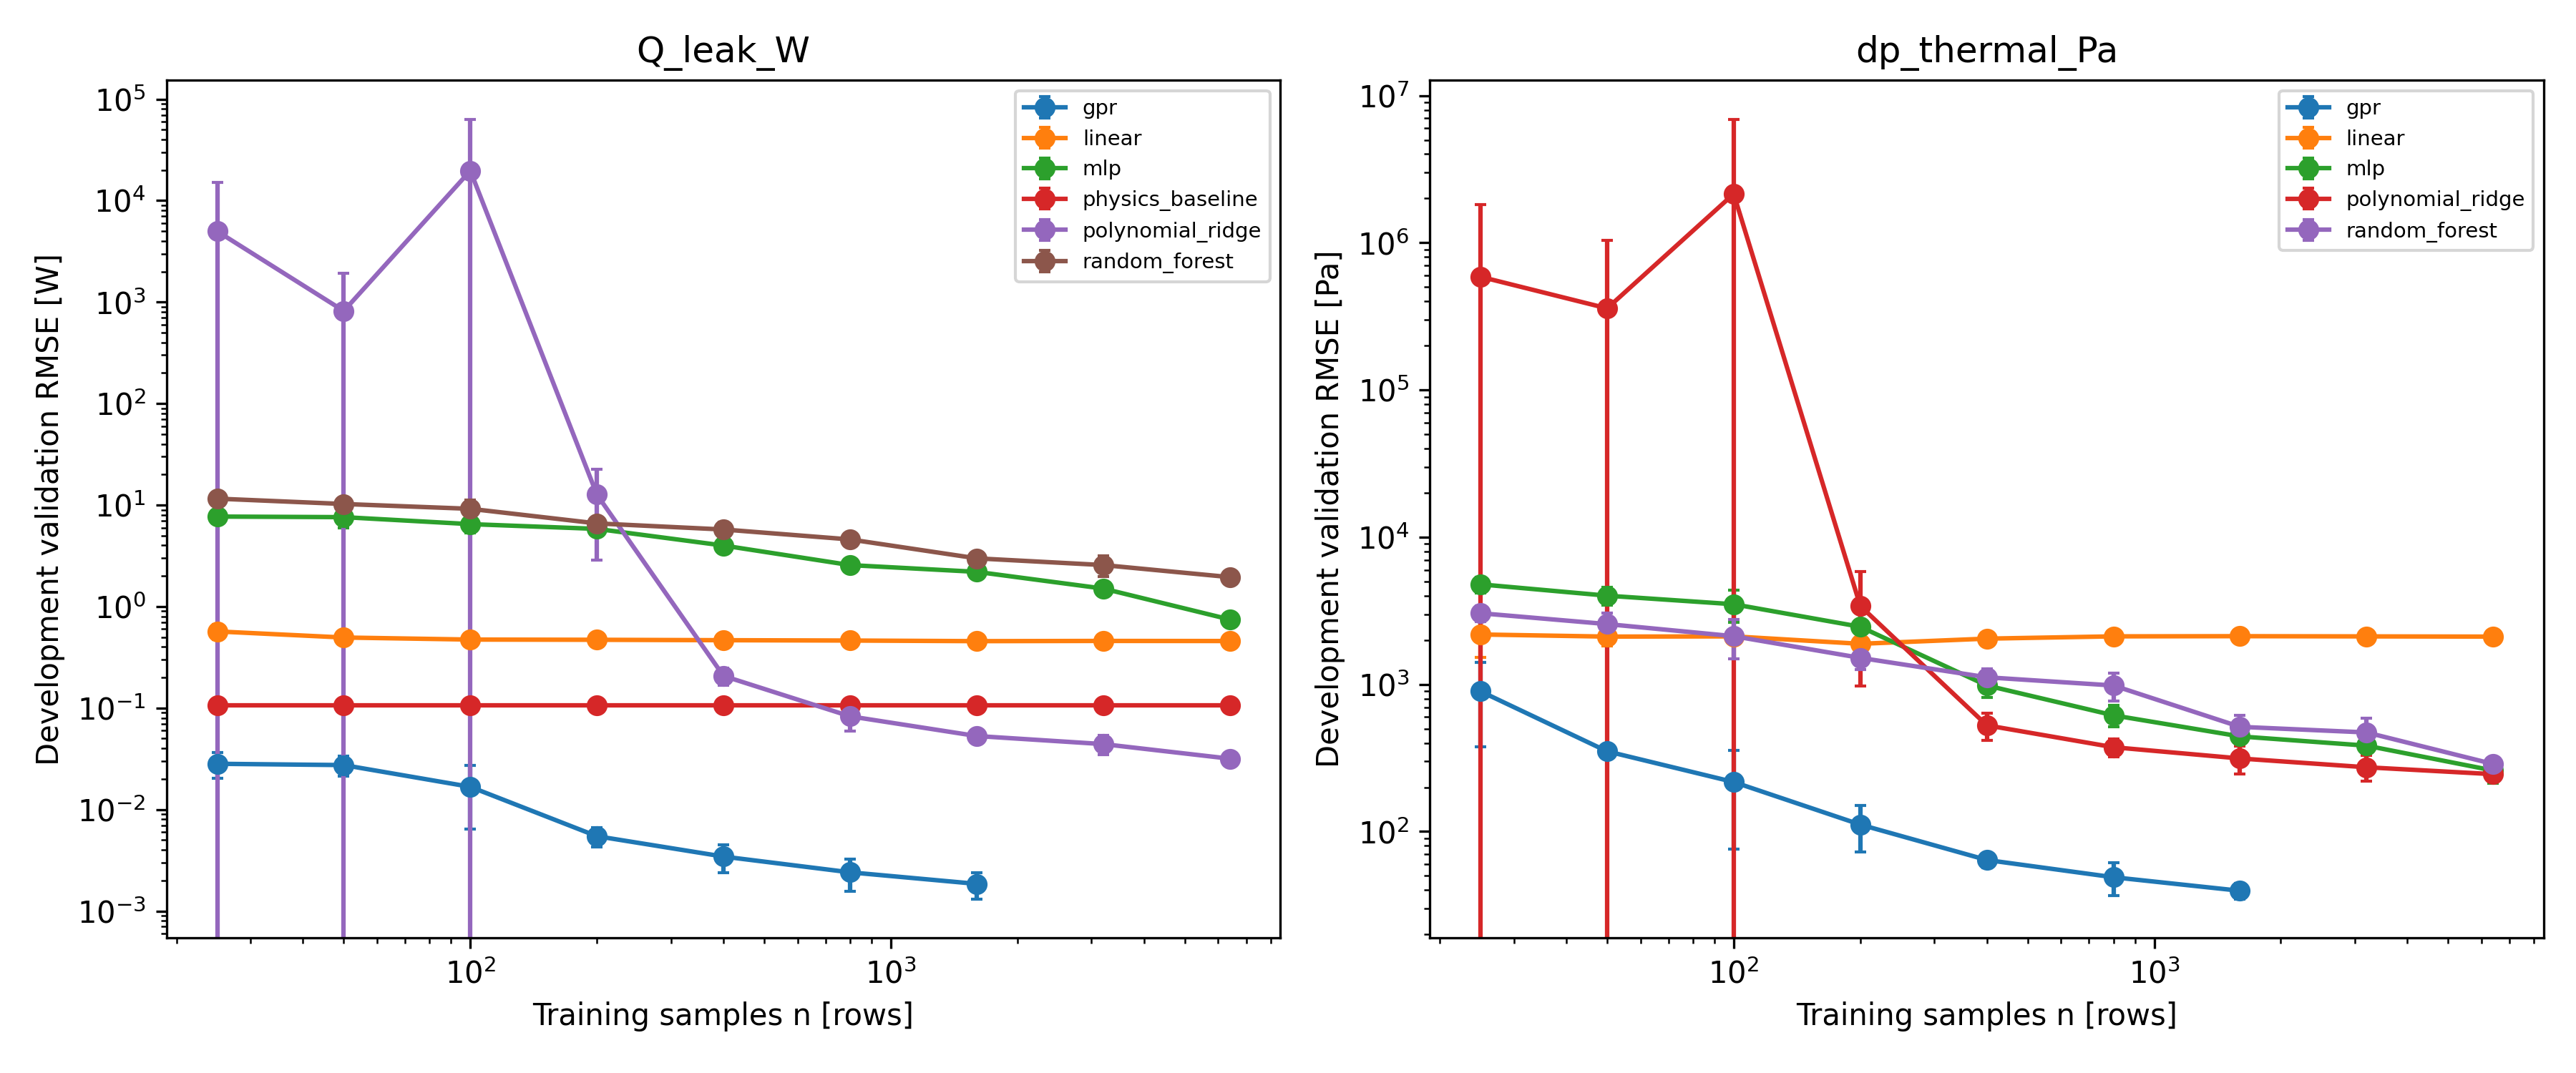

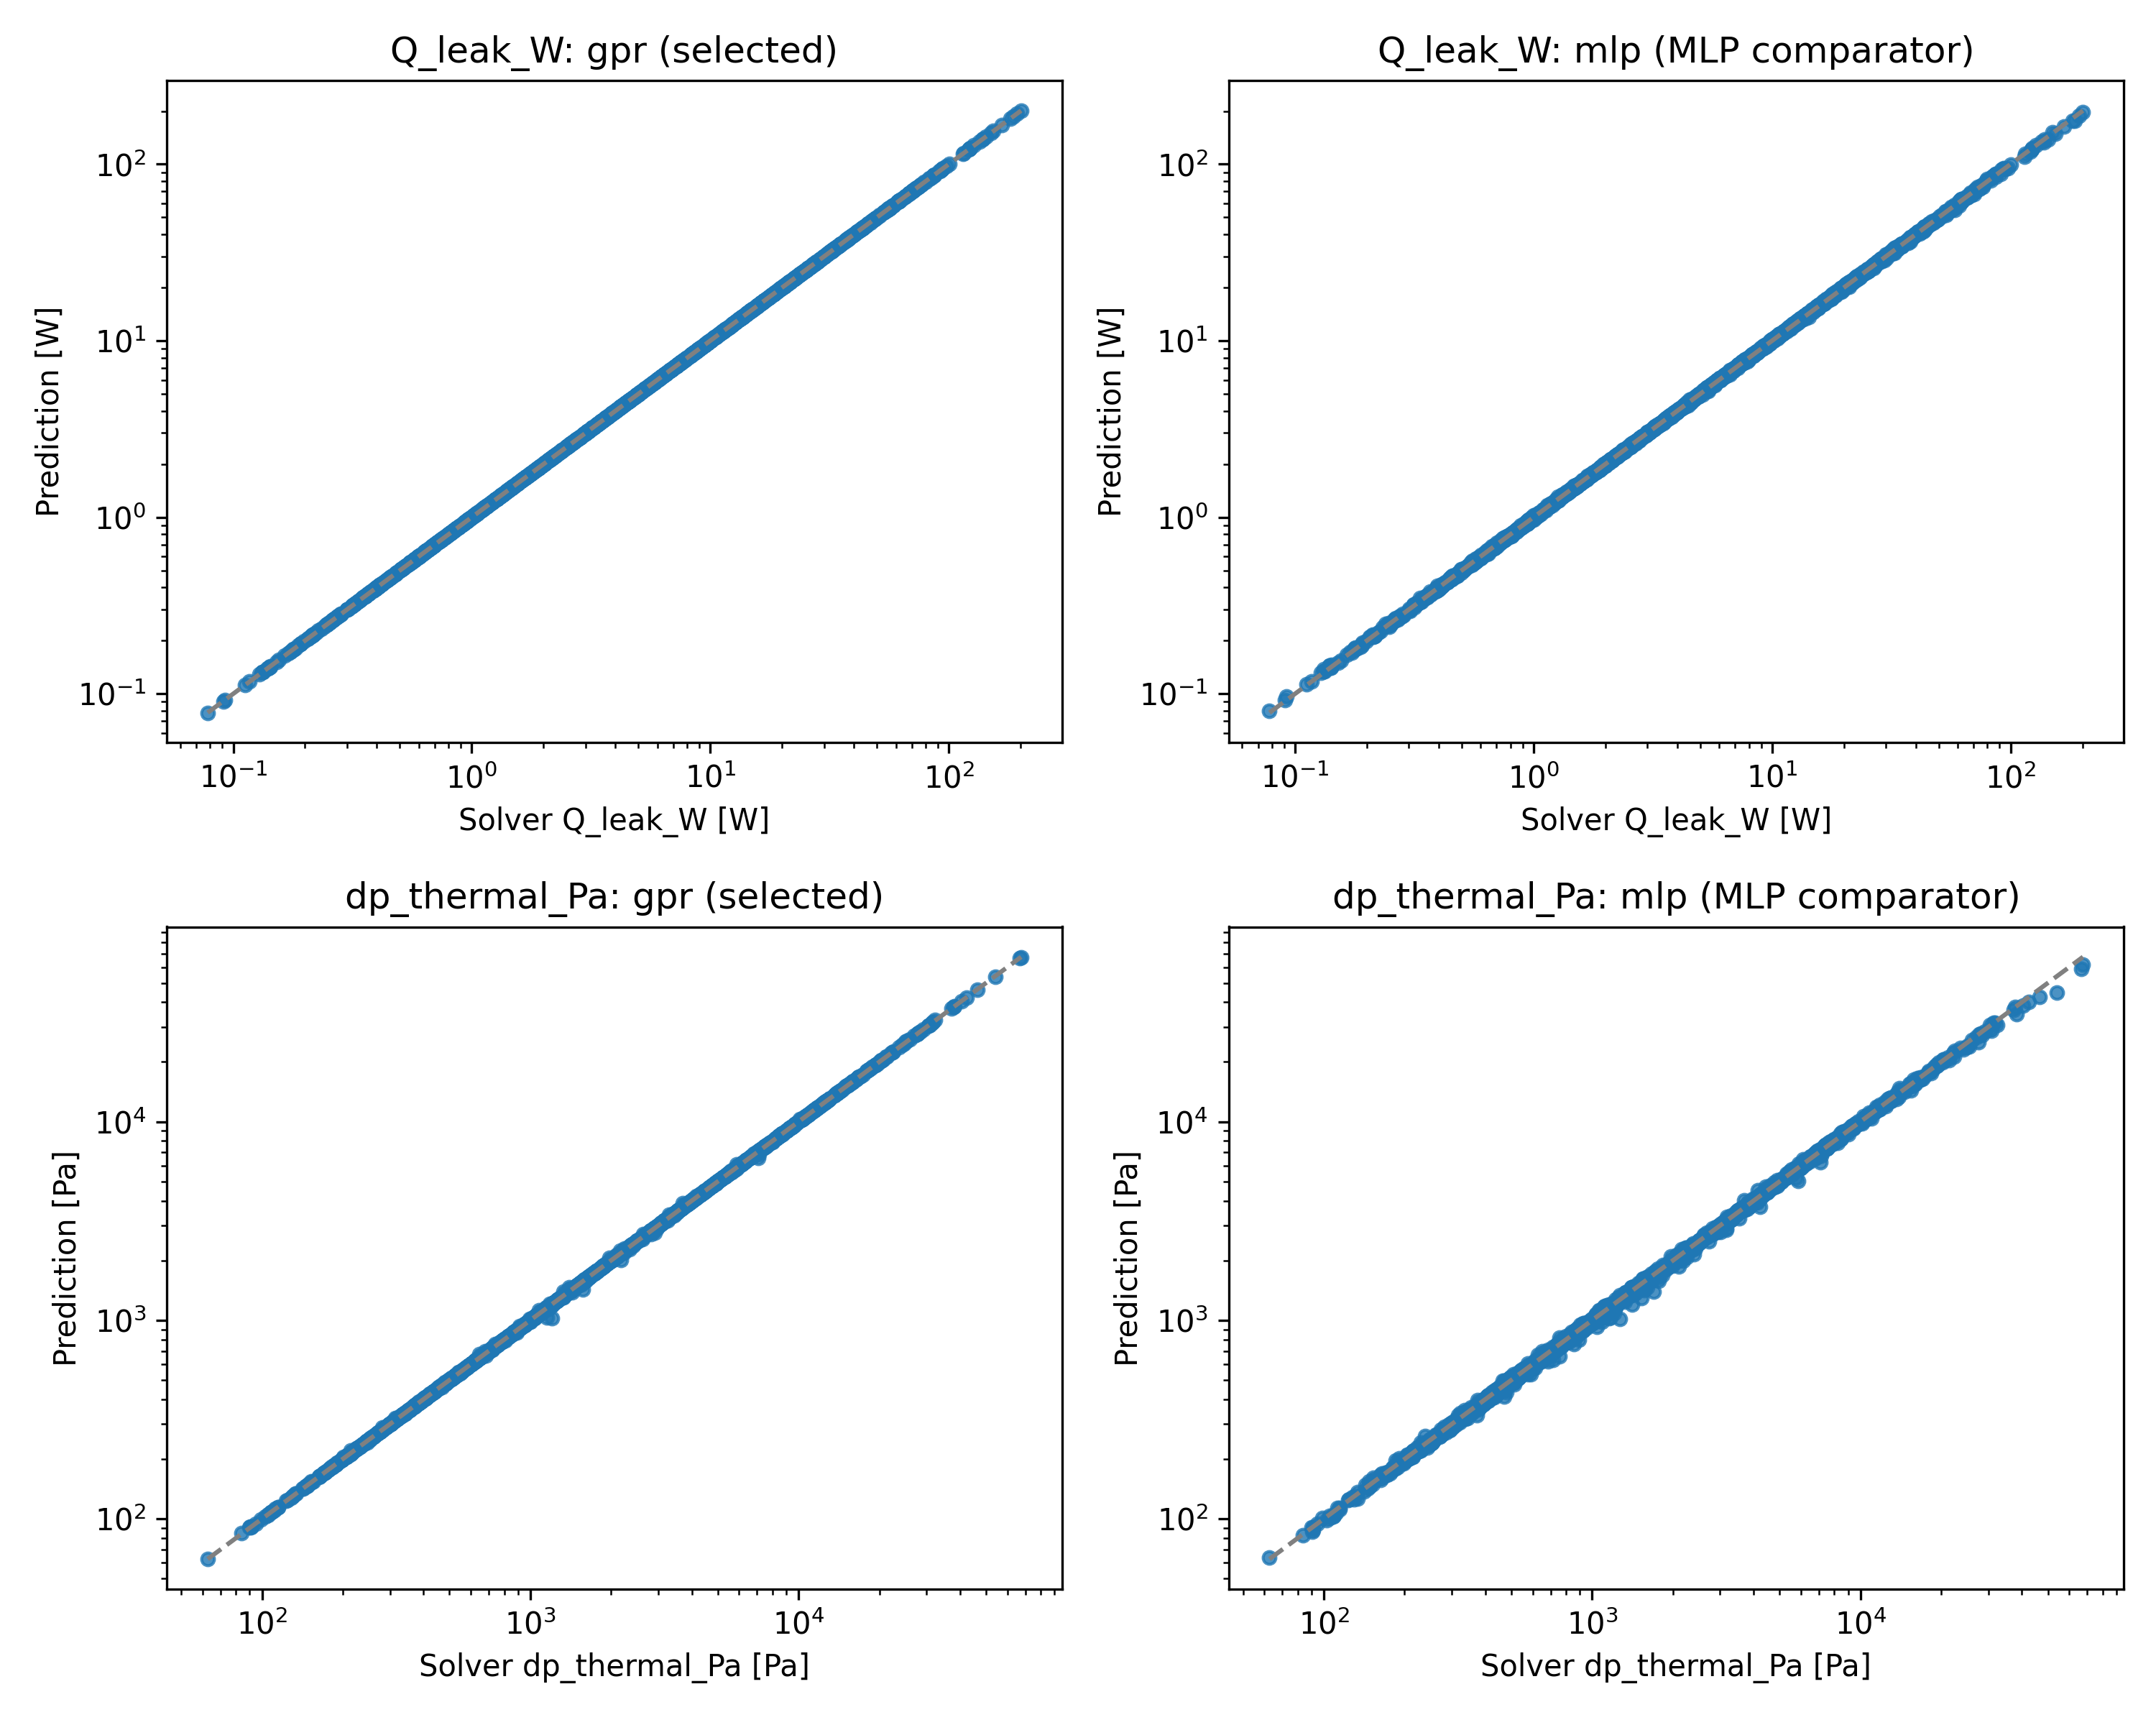

원본 경고는 results/T_warnings.csv에 보존했습니다.


In [9]:
table = pd.read_csv(results / 'T1_model_comparison.csv')
display(table[['target','model','actual_candidates','r2_mean_pm_std','rmse_mean_pm_std','mape_pct_mean_pm_std']])
display(Image(filename=str(results / 'F2_learning_curves.png'), width=1000))
display(Image(filename=str(results / 'F1_parity.png'), width=1000))
print('원본 경고는 results/T_warnings.csv에 보존했습니다.')

## 10. S1 최적화와 A·B·C
S1(6 Hz, 2 m, 80 kg/h, 열전도도 8×10⁻⁵ W/(m·K))에서 NSGA-II를 실행한다. 원본과 같은 개체 100개·200세대·seed 2026, 수력 계수 1.8을 사용한다. 목적은 열침입·전체 압력·외경 최소화이며 전체 압력 48.3 kPa 이하를 제약으로 둔다.

원본처럼 NSGA-II Pareto와 저장된 S1 격자 Pareto를 합쳐 비지배 후보를 고른다. 격자를 다시 계산하지 않으면서 후보 선정 기준을 일치시키기 위해서다.

A는 열침입 최소, C는 외경 최소, B는 Pareto 목적값을 0–1로 정규화한 뒤 이상점과의 거리가 가장 가까운 점이다. 이 후보들은 **대리모델 예측**이며 1D 솔버 재검증 결과가 아니다. 원본의 200×200 격자 비교와 S2·S3는 저장된 표·그림을 읽는다.

,role,D_mm,t_ins_mm,Q_leak_pred_W,dp_design_pred_Pa,D_o_mm
0,A,15.9773638,24.9998043,0.215231032,48264.7554,68.9769725
28499,B,29.5678392,6.04522613,0.878094713,14258.5864,44.6582915
32982,C,16.0127999,2,1.4446879,48291.9351,23.0127999


S1 NSGA-II 실행 시간: 18.4초


,role,D_mm_difference,t_ins_mm_difference,Q_leak_pred_W_difference,dp_design_pred_Pa_difference,D_o_mm_difference
0,A,0,3.55271368e-15,5.55111512e-17,0,0
1,B,0,0,0,0,0
2,C,0,4.4408921e-16,0,0,0


,scenario,role,D_mm,t_ins_mm,Q_leak_pred_W,dp_design_pred_Pa,D_o_mm
9,S2,A,16.2265481,24.9999999,7.2299937,48192.0755,69.2265479
10,S2,B,28.4221106,10.0904523,18.125646,19074.9721,51.6030151
11,S2,C,17.6042246,2.01192489,42.1266083,48296.4262,24.6280744
18,S3,A,21.8659778,25,0.252007893,48299.7995,74.8659778
19,S3,B,36.0603015,6.27638191,0.994890559,17910.9472,51.6130653
20,S3,C,21.9259574,2.00000007,1.85314901,48299.4366,28.9259575


,scenario,n_star,nsga_points,grid_points,nsga_hv,grid_hv,hv_ratio,ideal_Q_leak_pred_W,ideal_dp_design_pred_Pa,ideal_D_o_mm,nadir_Q_leak_pred_W,nadir_dp_design_pred_Pa,nadir_D_o_mm
0,S1,21.6666667,100,35799,1.08178585,1.15410895,0.937334248,0.215438235,5009.61862,23.201005,3.78898577,48294.11,103
1,S2,21.6666667,100,29229,0.95257971,1.02110519,0.93289087,7.26481736,7916.68754,24.7286432,52.741718,48290.0043,103
2,S3,14.4444444,100,29600,1.05992198,1.12251474,0.944238805,0.252398744,9297.48769,28.9296482,3.78915175,48283.3259,103


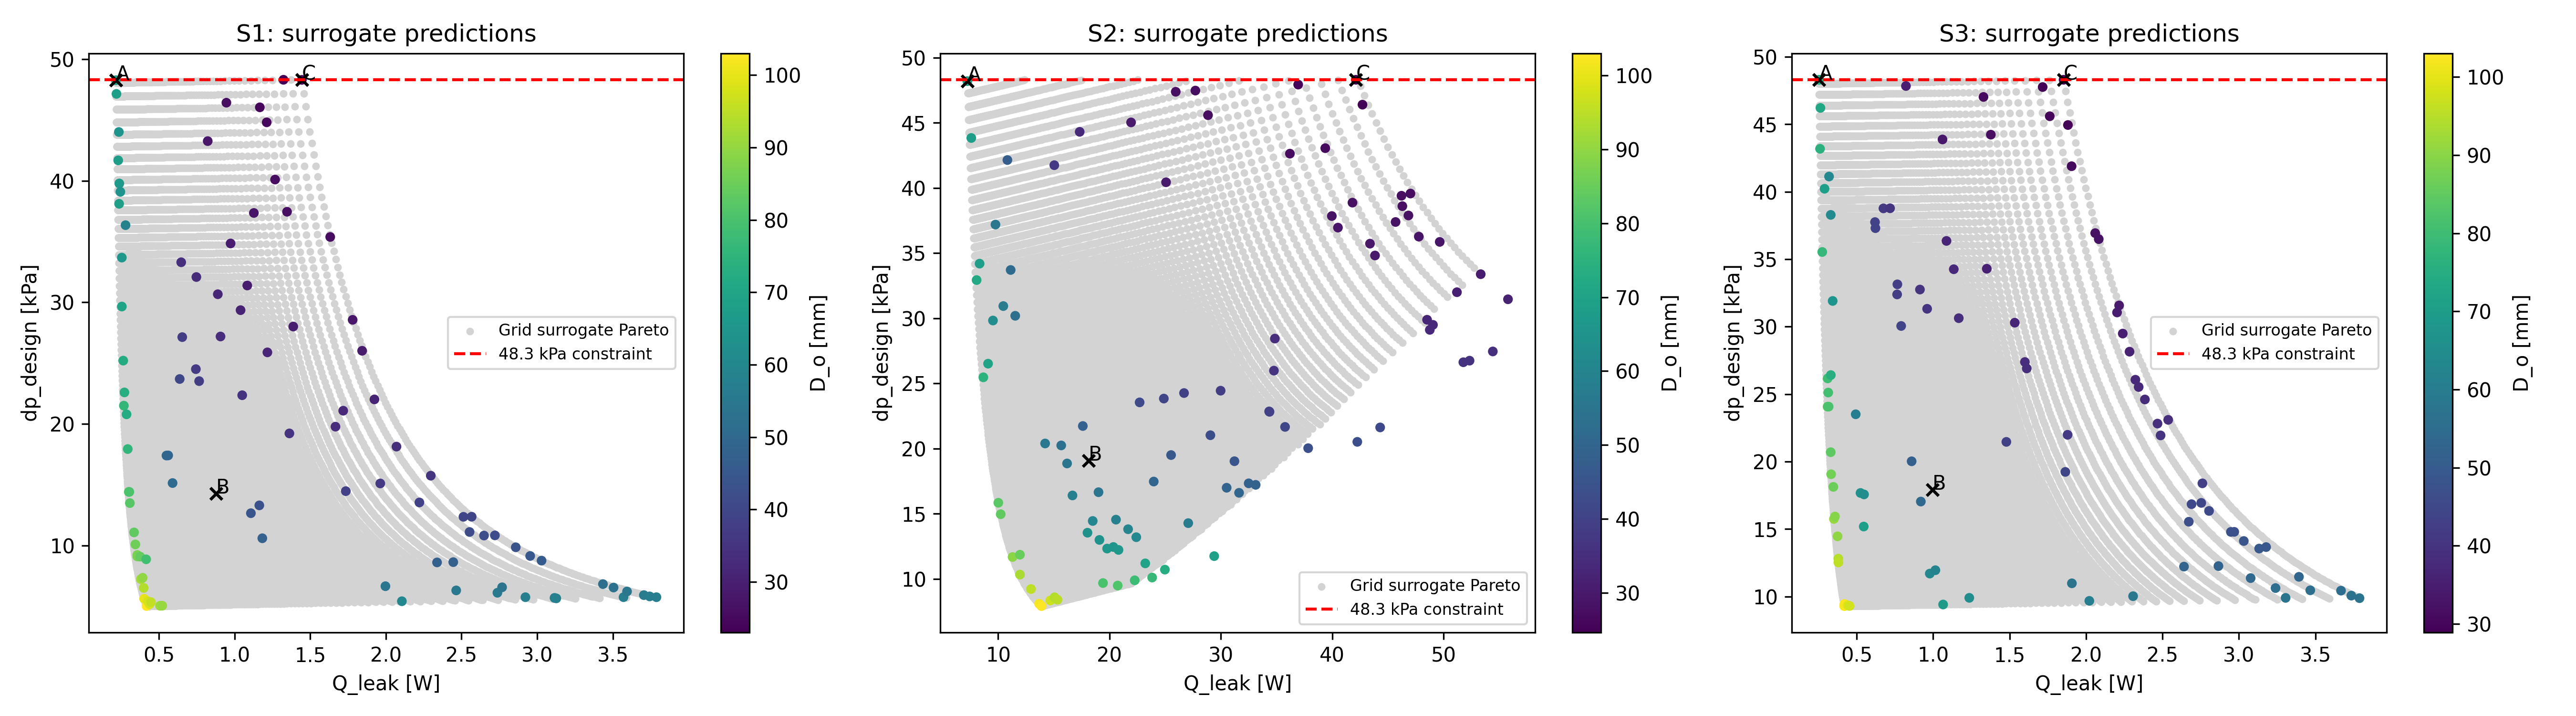

위 F4와 HV는 원본의 S1–S3 결과입니다. 비율 GPR 결과는 F4_gpr.png와 T3_gpr.csv에 있습니다.


In [10]:
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.optimize import minimize
import optimize as opt

# 원본 최적화 함수를 재사용하되, 파일 대신 이번에 학습한 모델을 메모리에 연결한다.
cache = opt.CachedModels.__new__(opt.CachedModels)
cache.models = {target: models[target+'__gpr'] for target in p.TARGETS}
cache.hyd_mode, cache.ratio_model = 'const', None
scenario = json.loads((base / 'full_pipeline' / 'configs' / 'scenarios.json').read_text())[0]
tick = time.perf_counter()
run = minimize(opt.design_problem(cache, scenario), NSGA2(pop_size=100), ('n_gen',200), seed=2026)
assert run.X is not None
front = opt.pareto(cache.evaluate(opt.design_frame(run.X, scenario)))
grid = pd.read_csv(ref / 'grid_pareto_S1.csv')
combined = opt.pareto(pd.concat([front, grid], ignore_index=True))
abc = opt.candidates(combined).query("role in ['A','B','C']")
show = ['role','D_mm','t_ins_mm','Q_leak_pred_W','dp_design_pred_Pa','D_o_mm']
display(abc[show])
print(f'S1 NSGA-II 실행 시간: {time.perf_counter()-tick:.1f}초')
old = pd.read_csv(results / 'const_verification_points.csv')
old_abc = old.loc[(old.scenario == 'S1') & old.role.isin(['A','B','C']), show]
abc_diff = abc[show].merge(old_abc, on='role', suffixes=('_notebook','_original'))
for col in show[1:]:
    abc_diff[col+'_difference'] = abc_diff[col+'_notebook']-abc_diff[col+'_original']
display(abc_diff[['role']+[c+'_difference' for c in show[1:]]])
abc_diff.to_csv(ref / 'notebook_S1_candidates_comparison.csv', index=False)
display(old.loc[(old.scenario != 'S1') & old.role.isin(['A','B','C']), ['scenario']+show])
display(pd.read_csv(results / 'const_hv_summary.csv'))
display(Image(filename=str(results / 'F4_const.png'), width=1100))
print('위 F4와 HV는 원본의 S1–S3 결과입니다. 비율 GPR 결과는 F4_gpr.png와 T3_gpr.csv에 있습니다.')

## 11. 결론과 한계
열침입은 단순한 물리식도 정확하다. AI는 열적 압력 손실의 비선형 관계를 표현하고, 수력 비율 보정은 제약 경계의 판정 오차를 줄인다. 정확도와 설계 안전성은 별개의 지표이므로 오차율과 false safe/unsafe를 함께 본다.

데이터는 1D 솔버 출력으로, 실험 정확도를 뜻하지 않는다. GPR은 계산량 때문에 개발 데이터 중 3,000개를 사용했다. 최적화는 학습 범위 안의 대리모델 설계 탐색이며 1D 재검증 결과는 별도다. 물성 변화·2상 유동·실제 제작 오차에 대한 타당성은 추가 검토가 필요하다.

다음 요약은 원본 대비 수치 차이와 실행 시간을 남긴다. 수치가 다르더라도 설정을 바꾸거나 재선정하지 않는다.

In [11]:
elapsed = time.perf_counter()-start
max_diff = {col: float(comparison[col+'_difference'].abs().max()) for col in ['r2','rmse','mape_pct']}
summary = {'elapsed_seconds': elapsed, 'max_abs_metric_difference': max_diff,
           'max_abs_prediction_difference': float(pred_diff['최대 예측 절대 차이'].max()),
           'test_rows': len(test), 'development_rows': len(dev),
           'gpr_rows': 3000, 'seed': 2026, 'finalize_rerun': False,
           'explanation': '학습된 커널의 전체 정밀도·부분표본·선정 설정을 고정. 남는 작은 차이는 커널 복원과 부동소수점 연산 경로 차이로 추정하며 재튜닝하지 않음.'}
(ref / 'notebook_execution.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2))
print(f'노트북 실행 시간: {elapsed:.1f}초 ({elapsed/60:.2f}분)')
display(pd.DataFrame([max_diff], index=['원본 대비 최대 절대 차이']))
print('GPR은 학습된 커널을 고정하여 재학습했으며, MLP는 원본 선정 설정으로 학습했습니다.')
print('GPR의 미세한 차이는 커널 복원과 부동소수점 연산 경로 차이로 추정합니다. MLP는 표시 정밀도에서 원본과 일치합니다.')

노트북 실행 시간: 24.3초 (0.40분)


,r2,rmse,mape_pct
원본 대비 최대 절대 차이,1.91735516e-13,1.18538324e-07,1.41675393e-09


GPR은 학습된 커널을 고정하여 재학습했으며, MLP는 원본 선정 설정으로 학습했습니다.
GPR의 미세한 차이는 커널 복원과 부동소수점 연산 경로 차이로 추정합니다. MLP는 표시 정밀도에서 원본과 일치합니다.
